# Tg error analysis

## 1. Goal and evaluation setup

Investigate where the current glass transition temperature (Tg)
model makes large prediction errors and identify possible
structure-related patterns.

- Reuse the shared row split from notebook 06.
- Use only training rows with an originally observed Tg value.
- Generate out-of-fold predictions using the same five folds
  and Random Forest + Morgan configuration as in notebook 06.
- Examine prediction bias, large errors and structural similarities.
- Keep the shared outer validation partition unused.

These analyses support model development. They do not provide
an independent final performance estimate.

# Fehleranalyse für Tg

## 1. Ziel und Aufbau der Auswertung

Es soll untersucht werden, bei welchen Fällen das aktuelle Modell zur Vorhersage der Glasübergangstemperatur (Tg) große Vorhersagefehler aufweist; zudem sollen mögliche strukturbedingte Muster identifiziert werden.

- Verwenden Sie die bereits festgelegte Aufteilung der Datensätze aus Notebook 06.
- Nutzen Sie ausschließlich Trainingsdaten, für die ein tatsächlich beobachteter Tg-Wert vorliegt.
- Erstellen Sie „Out-of-Fold“-Vorhersagen unter Verwendung derselben fünf Folds sowie der Konfiguration aus Notebook 06 (Random Forest in Kombination mit Morgan-Fingerprints).
- Untersuchen Sie den Vorhersage-Bias, große Fehler sowie strukturelle Ähnlichkeiten.
- Die für die externe Validierung reservierte Datenmenge bleibt dabei unberührt.

Diese Analysen dienen der Unterstützung der Modellentwicklung. Sie liefern keine unabhängige, abschließende Einschätzung der Modellgüte.

In [3]:
from pathlib import Path

import pandas as pd

# Locate the shared project root.
current_dir = Path.cwd().resolve()
PROJECT_ROOT = (
    current_dir
    if (current_dir / "pyproject.toml").is_file()
    else current_dir.parent
)

# Define the existing input files.
raw_path = PROJECT_ROOT / "data" / "raw" / "train.csv"
split_path = (
    PROJECT_ROOT
    / "results"
    / "06_shared_split"
    / "shared_split.csv"
)

# Check that both files exist.
assert raw_path.is_file(), f"Missing data file: {raw_path}"
assert split_path.is_file(), f"Missing split file: {split_path}"

# Load data without changing the original files.
raw_train = pd.read_csv(raw_path)
shared_split = pd.read_csv(split_path)

print("Project:", PROJECT_ROOT)
print("Raw data shape:", raw_train.shape)
print("Available Tg values:", raw_train["Tg"].notna().sum())
print("Split columns:", shared_split.columns.tolist())

display(shared_split.head())

Project: C:\Users\EMS-User\capstone_virtual_lab_mohamed_suhmi
Raw data shape: (7973, 7)
Available Tg values: 511
Split columns: ['row_index', 'id', 'partition']


,row_index,id,partition
0,0,87817,training
1,1,106919,training
2,2,388772,training
3,3,519416,training
4,4,539187,training


In [4]:
# Align the saved partition assignments with the original row order. (Richten von den gespeicherten Partitionszuordnungen an der ursprünglichen Zeilenreihenfolge aus.)
assert shared_split["row_index"].is_unique
assert shared_split["id"].is_unique

split_by_row = shared_split.set_index("row_index")
assert set(split_by_row.index) == set(raw_train.index)

split_by_row = split_by_row.loc[raw_train.index]

assert (
    split_by_row["id"].to_numpy() == raw_train["id"].to_numpy()
).all(), "Polymer IDs do not match the saved split."

assert split_by_row["partition"].notna().all()

# Select training rows with an originally observed Tg value.
training_mask = split_by_row["partition"].eq("training")
observed_tg_mask = raw_train["Tg"].notna()

tg_training = raw_train.loc[
    training_mask & observed_tg_mask,
    ["id", "SMILES", "Tg"],
].copy()

tg_training.index.name = "row_index"

print("Partition counts:")
print(split_by_row["partition"].value_counts())

print("\nTraining structures:", training_mask.sum())
print("Training structures with observed Tg:", len(tg_training))

display(tg_training.head())

Partition counts:
partition
training      6378
validation    1595
Name: count, dtype: int64

Training structures: 6378
Training structures with observed Tg: 424


,id,SMILES,Tg
row_index,,,
40,10142210,*NC(C)C(=O)NCC(=O)NCC(*)=O,208.639749
57,13838538,*CCCCCCSSCCCCSS*,-41.266724
63,16498242,*C=CCCCCCCCC*,-17.282022
108,30582999,*CCCCCCCCCCOC(=O)c1ccc(C(=O)NCCNC(=O)c2ccc(C(=...,4.250403
123,36217683,*c1nc2cc3sc(-c4cc(OCCCCCC)c(*)cc4OCCCCCC)nc3cc2s1,168.526313


## 2. Reuse the Morgan fingerprint settings

Load the fingerprint settings saved in notebook 06.
Use the same representation for the 424 training structures
with an originally observed Tg value.

In [5]:
import json

# Load the fingerprint settings from the reference experiment.
settings_path = (
    PROJECT_ROOT
    / "results"
    / "06_shared_split"
    / "morgan1024_settings.json"
)

assert settings_path.is_file(), f"Missing settings: {settings_path}"

with settings_path.open(encoding="utf-8") as file:
    morgan_settings = json.load(file)

display(pd.Series(morgan_settings, name="Setting"))

radius                   2
fp_size               1024
include_chirality     True
count_simulation     False
Name: Setting, dtype: object

In [6]:
import numpy as np
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

# Reuse the saved fingerprint settings.
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=morgan_settings["radius"],
    fpSize=morgan_settings["fp_size"],
    includeChirality=morgan_settings["include_chirality"],
    countSimulation=morgan_settings["count_simulation"],
)

# Convert SMILES into molecular graphs.
tg_molecules = tg_training["SMILES"].map(Chem.MolFromSmiles)

assert tg_molecules.notna().all(), "Some SMILES could not be parsed."

# Calculate one binary fingerprint per polymer.
fingerprint_rows = [
    morgan_generator.GetFingerprintAsNumPy(molecule)
    for molecule in tg_molecules
]

# Preserve the original row identifiers and order.
X_tg = pd.DataFrame(
    np.stack(fingerprint_rows),
    index=tg_training.index,
    columns=[
        f"morgan_{position}"
        for position in range(morgan_settings["fp_size"])
    ],
    dtype=np.uint8,
)

y_tg = tg_training["Tg"].copy()

assert X_tg.index.equals(y_tg.index)
assert X_tg.shape == (len(tg_training), morgan_settings["fp_size"])
assert np.isin(X_tg.to_numpy(), [0, 1]).all()

print("Fingerprint matrix:", X_tg.shape)
print("Target values:", y_tg.shape)
print("Missing fingerprint values:", X_tg.isna().sum().sum())

display(X_tg.iloc[:5, :10])

Fingerprint matrix: (424, 1024)
Target values: (424,)
Missing fingerprint values: 0


,morgan_0,morgan_1,morgan_2,morgan_3,morgan_4,morgan_5,morgan_6,morgan_7,morgan_8,morgan_9
row_index,,,,,,,,,,
40,0,1,0,0,0,0,0,0,0,0
57,1,0,0,0,0,0,0,0,0,0
63,0,0,0,0,0,0,0,0,0,0
108,0,0,0,0,0,0,0,0,1,0
123,0,0,0,0,0,0,0,0,0,0


## 3. Reproduce the reference row order and CV folds

Reconstruct the training-row order used in notebook 06.
Verify that the partition matches the saved split before
creating the same five shuffled CV folds with random_state=42.

In [7]:
from sklearn.model_selection import KFold, train_test_split

# Reconstruct the exact row order from notebook 06.
reference_training_indices, reference_validation_indices = train_test_split(
    raw_train.index.to_numpy(),
    test_size=0.20,
    random_state=42,
    shuffle=True,
)

# Verify the assignments against the saved split.
assert set(reference_training_indices) == set(
    split_by_row.index[split_by_row["partition"].eq("training")]
)
assert set(reference_validation_indices) == set(
    split_by_row.index[split_by_row["partition"].eq("validation")]
)

# Select observed Tg rows in the reference training order.
reference_training_rows = raw_train.loc[reference_training_indices]

tg_reference_indices = reference_training_rows.index[
    reference_training_rows["Tg"].notna()
]

assert set(tg_reference_indices) == set(tg_training.index)

# Align structures, fingerprints and targets in that order.
tg_training = tg_training.loc[tg_reference_indices].copy()
X_tg = X_tg.loc[tg_reference_indices].copy()
y_tg = y_tg.loc[tg_reference_indices].copy()

assert X_tg.index.equals(y_tg.index)
assert X_tg.index.equals(tg_training.index)

# Reproduce the five folds from notebook 06.
tg_cv_folds = list(
    KFold(
        n_splits=5,
        shuffle=True,
        random_state=42,
    ).split(X_tg)
)

display(pd.DataFrame([
    {
        "fold": fold_number,
        "training_rows": len(train_positions),
        "held_out_rows": len(held_out_positions),
    }
    for fold_number, (train_positions, held_out_positions)
    in enumerate(tg_cv_folds, start=1)
]))

,fold,training_rows,held_out_rows
0,1,339,85
1,2,339,85
2,3,339,85
3,4,339,85
4,5,340,84


## 4. Generate out-of-fold predictions

Train one Random Forest per fold using the reference configuration.
Predict Tg only for the rows held out from that training run.

Each training structure receives exactly one out-of-fold prediction.
The shared outer validation partition remains unused.

Define the signed error as predicted Tg minus observed Tg:
positive values indicate overprediction, negative values underprediction.

In [8]:
import sys

# Import the same model definition used in notebook 06.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.polymer_modeling import make_model, mae

assert X_tg.index.equals(y_tg.index)
assert np.isfinite(y_tg.to_numpy()).all()

# Prepare storage for one prediction per training structure.
oof_predictions = np.full(len(y_tg), np.nan)
oof_fold_numbers = np.zeros(len(y_tg), dtype=int)
prediction_counts = np.zeros(len(y_tg), dtype=int)
fold_results = []

for fold_number, (train_positions, held_out_positions) in enumerate(
    tg_cv_folds,
    start=1,
):
    # Create a fresh model for this fold.
    model = make_model("random_forest", n_jobs=1)

    model.fit(
        X_tg.iloc[train_positions],
        y_tg.iloc[train_positions],
    )

    predictions = model.predict(X_tg.iloc[held_out_positions])

    # Return predictions to their matching row positions.
    oof_predictions[held_out_positions] = predictions
    oof_fold_numbers[held_out_positions] = fold_number
    prediction_counts[held_out_positions] += 1

    fold_mae = mae(y_tg.iloc[held_out_positions], predictions)

    fold_results.append({
        "fold": fold_number,
        "held_out_rows": len(held_out_positions),
        "mae": fold_mae,
    })

    print(f"Fold {fold_number} completed — MAE: {fold_mae:.6f}")

# Verify complete and unique prediction coverage.
assert (prediction_counts == 1).all()
assert np.isfinite(oof_predictions).all()

# Build the row-level error table.
tg_errors = tg_training[["id", "SMILES", "Tg"]].copy()
tg_errors = tg_errors.rename(columns={"Tg": "observed_tg"})
tg_errors["predicted_tg"] = oof_predictions
tg_errors["fold"] = oof_fold_numbers

tg_errors["signed_error"] = (
    tg_errors["predicted_tg"] - tg_errors["observed_tg"]
)
tg_errors["absolute_error"] = tg_errors["signed_error"].abs()

tg_fold_results = pd.DataFrame(fold_results)

display(tg_fold_results.round(6))

print(
    "Mean fold MAE:",
    f"{tg_fold_results['mae'].mean():.6f}",
)
print(
    "Overall OOF MAE:",
    f"{tg_errors['absolute_error'].mean():.6f}",
)

display(tg_errors.head())

Fold 1 completed — MAE: 50.228072
Fold 2 completed — MAE: 54.707263
Fold 3 completed — MAE: 48.715243
Fold 4 completed — MAE: 58.007778
Fold 5 completed — MAE: 68.527561


,fold,held_out_rows,mae
0,1,85,50.228072
1,2,85,54.707263
2,3,85,48.715243
3,4,85,58.007778
4,5,84,68.527561


Mean fold MAE: 56.037183
Overall OOF MAE: 56.007725


,id,SMILES,observed_tg,predicted_tg,fold,signed_error,absolute_error
7706,2077226118,*C(=O)c1ccc2c(c1)C(=O)N(c1ccc(Oc3ccc(Oc4ccc(Oc...,126.255179,219.023011,1,92.767831,92.767831
6113,1656589637,*Nc1c(C)c(C)c(NC(=O)c2ccc(C(*)=O)cc2)c(C)c1C,205.655243,166.830247,5,-38.824996,38.824996
4526,1218861482,*OC(C)CCOC(=O)c1cccc(C(*)=O)c1,-42.286193,79.676160,3,121.962353,121.962353
7228,1952404953,*C(=O)c1ccc2c(c1)C(=Nc1cccc(N=C3OC(=O)c4ccc(*)...,246.658418,191.628617,2,-55.029801,55.029801
432,119301714,*CCNC(=O)CCCCCCCC(=O)NCCNC(=O)C(=O)N*,112.525684,16.053046,4,-96.472638,96.472638


In [9]:
# Load the saved fold results from notebook 06.
reference_path = (
    PROJECT_ROOT
    / "results"
    / "06_shared_split"
    / "stage1_morgan1024_rf_cv_folds.csv"
)

reference_results = pd.read_csv(reference_path)

reference_tg = reference_results.loc[
    reference_results["target"].eq("Tg")
    & reference_results["feature_set"].eq("morgan1024")
    & reference_results["model"].eq("random_forest"),
    ["fold", "mae"],
].rename(columns={"mae": "reference_mae"})

# Match results by fold number.
tg_fold_comparison = tg_fold_results.merge(
    reference_tg,
    on="fold",
    how="left",
    validate="one_to_one",
)

assert len(tg_fold_comparison) == 5
assert tg_fold_comparison["reference_mae"].notna().all()

tg_fold_comparison["difference"] = (
    tg_fold_comparison["mae"]
    - tg_fold_comparison["reference_mae"]
)

display(tg_fold_comparison.round(6))

np.testing.assert_allclose(
    tg_fold_comparison["mae"],
    tg_fold_comparison["reference_mae"],
    rtol=0,
    atol=1e-6,
)

print("Reference check passed: all five fold MAEs match.")

,fold,held_out_rows,mae,reference_mae,difference
0,1,85,50.228072,50.228072,0.0
1,2,85,54.707263,54.707263,0.0
2,3,85,48.715243,48.715243,0.0
3,4,85,58.007778,58.007778,0.0
4,5,84,68.527561,68.527561,0.0


Reference check passed: all five fold MAEs match.


## 5. Observed versus predicted Tg

Plot the out-of-fold predictions against the original Tg values.

The diagonal represents perfect predictions:
- Points above the diagonal indicate overprediction.
- Points below the diagonal indicate underprediction.

Inspect whether errors vary across the observed Tg range.

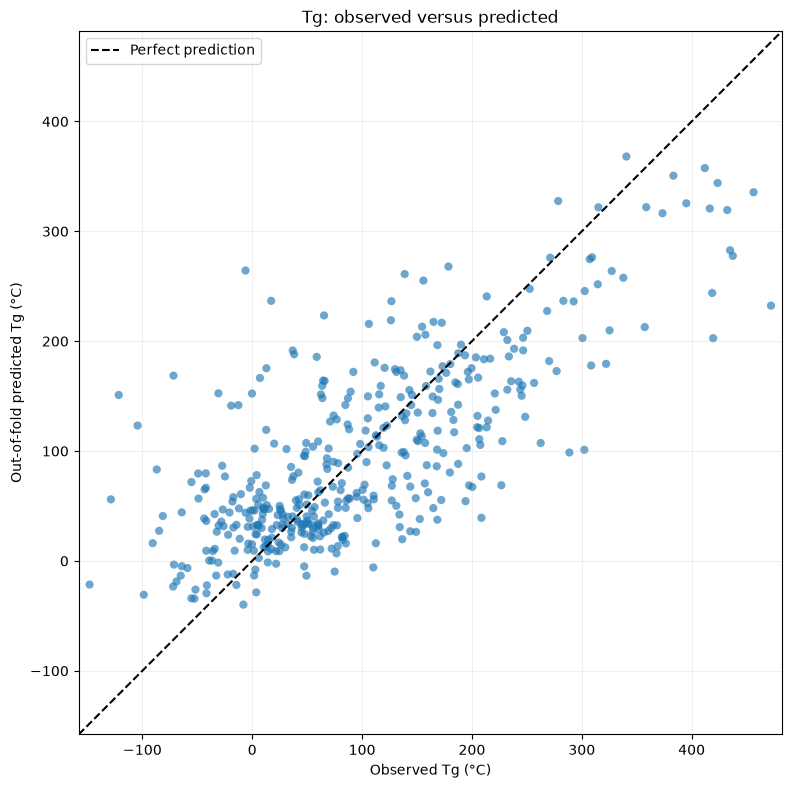

In [10]:
import matplotlib.pyplot as plt

observed = tg_errors["observed_tg"]
predicted = tg_errors["predicted_tg"]

# Use the same scale on both axes.
lower_limit = min(observed.min(), predicted.min()) - 10
upper_limit = max(observed.max(), predicted.max()) + 10

fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    observed,
    predicted,
    alpha=0.65,
    s=35,
    edgecolors="none",
)

# Perfect predictions lie on this diagonal.
ax.plot(
    [lower_limit, upper_limit],
    [lower_limit, upper_limit],
    color="black",
    linestyle="--",
    label="Perfect prediction",
)

ax.set(
    xlim=(lower_limit, upper_limit),
    ylim=(lower_limit, upper_limit),
    xlabel="Observed Tg (°C)",
    ylabel="Out-of-fold predicted Tg (°C)",
    title="Tg: observed versus predicted",
)

ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()

### Initial observations

The out-of-fold predictions show a tendency towards the middle
of the observed Tg range:

- Low observed Tg values are frequently overpredicted.
- High observed Tg values are predominantly underpredicted.
- Substantial prediction errors also occur in the middle range.

These observations describe the error pattern but do not establish
its cause. Next, quantify errors across observed Tg ranges.

In [11]:
# Group structures by their originally observed Tg.
tg_error_groups = tg_errors.copy()

tg_error_groups["tg_range"] = pd.qcut(
    tg_error_groups["observed_tg"],
    q=4,
    duplicates="drop",
)

# Summarise error size and direction within each group.
tg_range_summary = (
    tg_error_groups
    .groupby("tg_range", observed=True)
    .agg(
        count=("observed_tg", "size"),
        observed_min=("observed_tg", "min"),
        observed_max=("observed_tg", "max"),
        mean_signed_error=("signed_error", "mean"),
        mae=("absolute_error", "mean"),
        median_absolute_error=("absolute_error", "median"),
    )
)

display(tg_range_summary.round(2))

,count,observed_min,observed_max,mean_signed_error,mae,median_absolute_error
tg_range,,,,,,
"(-148.031, 13.881]",106,-148.03,13.26,66.01,67.91,50.03
"(13.881, 74.54]",106,14.09,74.04,11.72,33.63,20.23
"(74.54, 164.458]",106,75.04,164.32,-16.43,47.21,42.11
"(164.458, 472.25]",106,164.86,472.25,-68.84,75.28,69.02


### Quantitative error analysis by observed Tg range

The 424 labelled structures were divided into four equally sized
groups based on their observed Tg values.

The analysis confirms a systematic prediction bias:

- Low Tg values are overpredicted (mean signed error: +66.01 °C).
- High Tg values are underpredicted (mean signed error: -68.84 °C).
- The lowest MAE occurs in the second Tg group (33.63 °C).
- The highest MAE occurs in the highest Tg group (75.28 °C).

This pattern is consistent with regression towards the mean.
The model has difficulties capturing extreme Tg values.

The underlying reasons require further investigation.

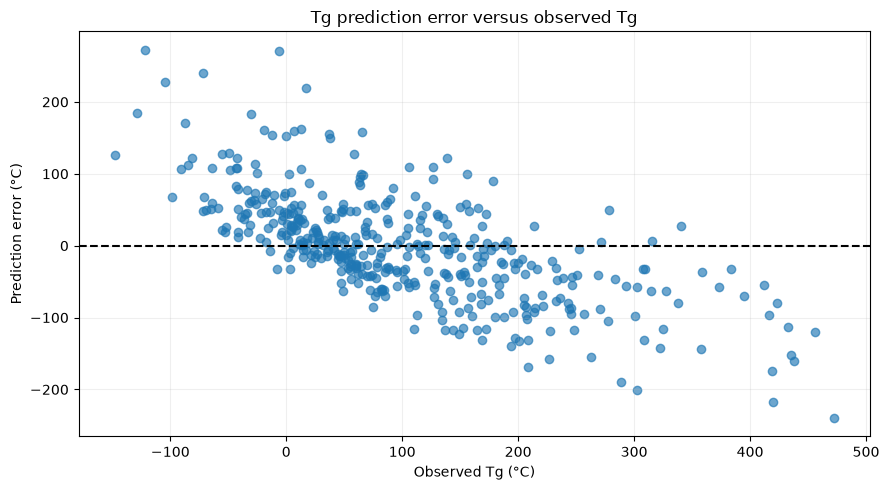

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    tg_errors["observed_tg"],
    tg_errors["signed_error"],
    alpha=0.65,
)

ax.axhline(0, linestyle="--", color="black")

ax.set_xlabel("Observed Tg (°C)")
ax.set_ylabel("Prediction error (°C)")
ax.set_title("Tg prediction error versus observed Tg")

ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Inspect the largest out-of-fold errors

Identify the ten structures with the largest absolute prediction errors.
Inspect their observed Tg, predicted Tg and error direction.

Calculate their contribution to the total absolute error.
Large prediction errors alone are not a reason to remove structures.

In [13]:
# Select the ten largest absolute errors.
largest_tg_errors = tg_errors.nlargest(
    10,
    "absolute_error",
).copy()

display(
    largest_tg_errors[
        [
            "id",
            "observed_tg",
            "predicted_tg",
            "signed_error",
            "absolute_error",
            "fold",
            "SMILES",
        ]
    ].round(2)
)

# Quantify how much these structures contribute to the total error.
total_absolute_error = tg_errors["absolute_error"].sum()
top10_absolute_error = largest_tg_errors["absolute_error"].sum()

top10_error_share = (
    100 * top10_absolute_error / total_absolute_error
)

print(
    f"These 10 structures represent "
    f"{100 * len(largest_tg_errors) / len(tg_errors):.2f}% "
    f"of the analysed structures."
)

print(
    f"They account for {top10_error_share:.2f}% "
    f"of the total absolute error."
)

,id,observed_tg,predicted_tg,signed_error,absolute_error,fold,SMILES
2725,742571113,-121.52,151.02,272.54,272.54,5,*c1cc(*)c(O)c(C=Nc2ccc(F)cc2)c1
7559,2042324873,-6.10,264.33,270.43,270.43,5,*C=C(*)c1nc2ccccc2n1C
3035,822072702,-71.68,168.66,240.34,240.34,2,*C(=O)Oc1ccc(OC(=O)c2ccc3c(c2)C(=O)N(c2ccc(N4C...
3358,918773447,472.25,232.40,-239.85,239.85,5,*c1ccc(-c2ccc(N3C(=O)c4cc5c(cc4C3=O)C(C(F)(F)F...
6559,1784177503,-104.34,123.20,227.53,227.53,5,*Oc1cccc(OC(=O)Oc2ccc(OC(*)=O)cc2)c1
4274,1153274738,17.25,236.73,219.48,219.48,5,*C(=O)c1ccc(N=Nc2ccc(C(=O)N3C(=O)N(*)C4(CCCC4)...
991,270662526,419.58,202.73,-216.85,216.85,4,*c1ccc(Sc2ccc(-c3nc(-c4cccc(-c5nnc(-c6ccccc6)c...
1800,483787501,302.35,101.12,-201.24,201.24,2,*C(=O)c1ccc(N=Nc2ccc(C(=O)N3C(=O)N(*)C(C)(C)C3...
5676,1538292595,288.71,98.66,-190.05,190.05,2,*Oc1c(C(=O)Oc2ccc(OC(=O)c3ccc4ccccc4c3Oc3nc(*)...
3219,876238099,-128.63,56.00,184.63,184.63,5,*c1ccc(N(*)CCCCCC)cc1


These 10 structures represent 2.36% of the analysed structures.
They account for 9.53% of the total absolute error.


### Structural inspection of the largest errors

The ten largest errors represent 2.36% of the analysed structures
and contribute 9.53% of the total absolute error.
Six of these cases belong to fold 5.

Inspect the molecular structures for possible shared characteristics.
Any resulting explanations remain hypotheses and require comparison
with structures that have smaller prediction errors.

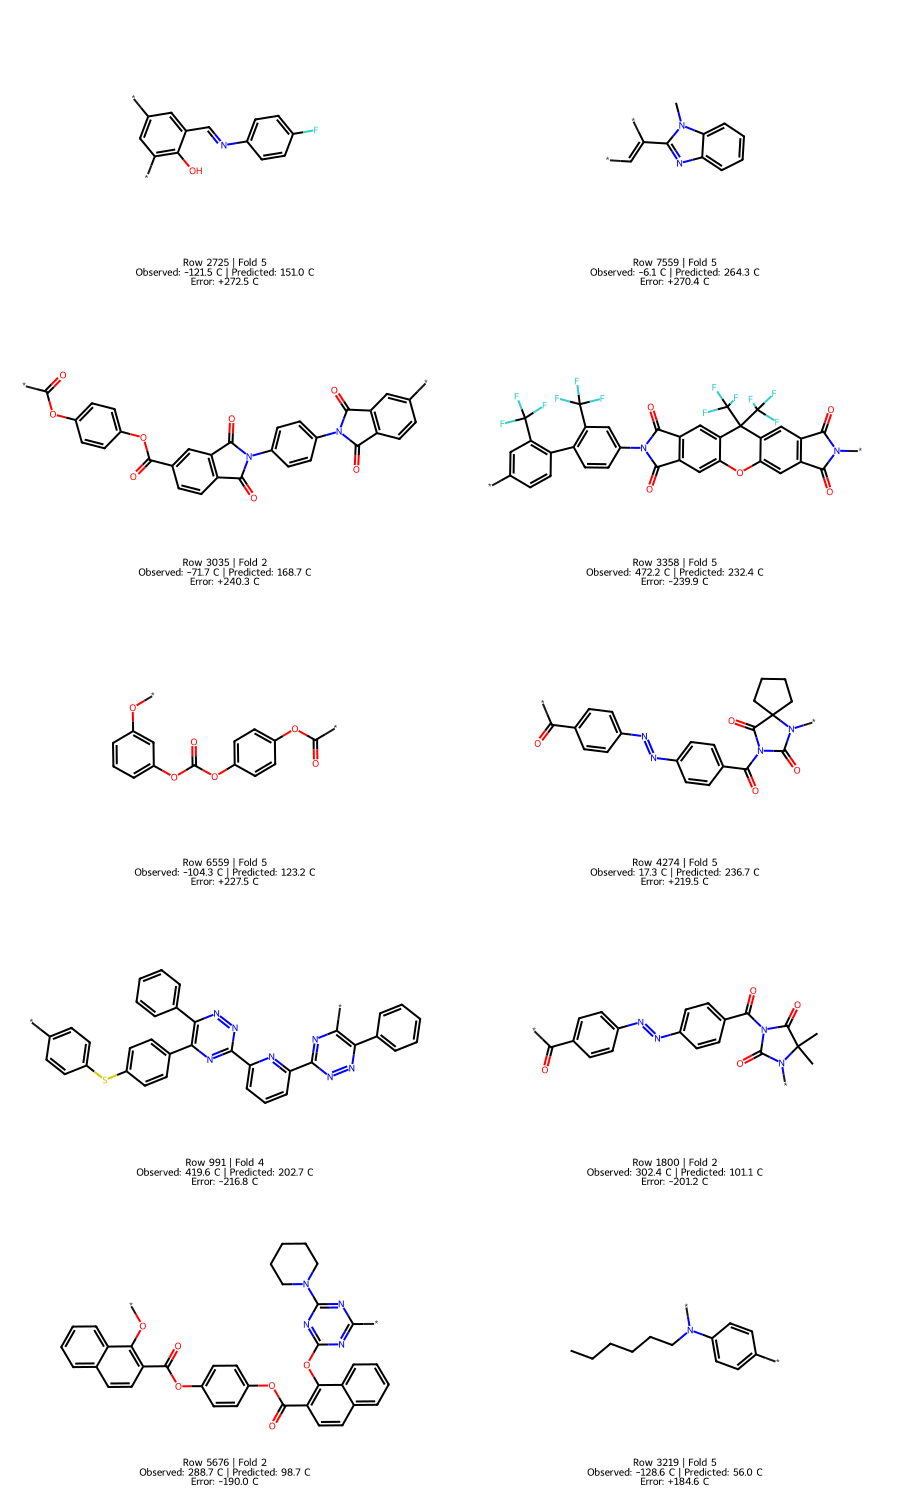

In [14]:
from rdkit.Chem import Draw

# Parse the ten structures in descending error order.
largest_error_molecules = [
    Chem.MolFromSmiles(smiles)
    for smiles in largest_tg_errors["SMILES"]
]

assert all(
    molecule is not None
    for molecule in largest_error_molecules
)

# Label each structure with its row index and prediction error.
structure_legends = []

for row_index, row in largest_tg_errors.iterrows():
    structure_legends.append(
        f"Row {row_index} | Fold {int(row['fold'])}\n"
        f"Observed: {row['observed_tg']:.1f} C | "
        f"Predicted: {row['predicted_tg']:.1f} C\n"
        f"Error: {row['signed_error']:+.1f} C"
    )

# Display two structures per row.
structure_grid = Draw.MolsToGridImage(
    largest_error_molecules,
    molsPerRow=2,
    subImgSize=(450, 300),
    legends=structure_legends,
    useSVG=True,
)

display(structure_grid)

In [15]:
from rdkit import DataStructs

# Generate RDKit bit vectors in the current reference row order.
tg_bit_fingerprints = [
    morgan_generator.GetFingerprint(molecule)
    for molecule in tg_molecules.loc[X_tg.index]
]

nearest_records = []

for fold_number, (train_positions, held_out_positions) in enumerate(
    tg_cv_folds,
    start=1,
):
    training_fingerprints = [
        tg_bit_fingerprints[position]
        for position in train_positions
    ]

    for position in held_out_positions:
        # Compare only with structures used to train this fold.
        similarities = DataStructs.BulkTanimotoSimilarity(
            tg_bit_fingerprints[position],
            training_fingerprints,
        )

        best_match = int(np.argmax(similarities))
        nearest_position = train_positions[best_match]

        nearest_records.append({
            "row_index": X_tg.index[position],
            "nearest_training_row": X_tg.index[nearest_position],
            "max_training_similarity": similarities[best_match],
            "nearest_training_tg": y_tg.iloc[nearest_position],
        })

nearest_training = (
    pd.DataFrame(nearest_records)
    .set_index("row_index")
)

assert nearest_training.index.is_unique
assert set(nearest_training.index) == set(tg_errors.index)

tg_similarity_errors = tg_errors.join(
    nearest_training,
    validate="one_to_one",
)

# Inspect the same ten largest errors.
display(
    tg_similarity_errors.loc[
        largest_tg_errors.index,
        [
            "observed_tg",
            "predicted_tg",
            "absolute_error",
            "max_training_similarity",
            "nearest_training_row",
            "nearest_training_tg",
        ],
    ].round(3)
)

,observed_tg,predicted_tg,absolute_error,max_training_similarity,nearest_training_row,nearest_training_tg
2725,-121.521,151.020,272.541,0.283,7607,139.123
7559,-6.104,264.328,270.432,0.371,7436,66.130
3035,-71.681,168.656,240.337,0.688,7706,126.255
3358,472.250,232.395,239.855,0.403,5137,302.653
6559,-104.338,123.197,227.535,0.633,7429,105.050
4274,17.254,236.730,219.476,0.674,1800,302.355
991,419.578,202.732,216.846,0.244,2265,64.587
1800,302.355,101.117,201.237,0.674,4274,17.254
5676,288.708,98.661,190.046,0.300,6115,227.701
3219,-128.630,55.998,184.628,0.371,2850,14.340


### Initial similarity findings

The largest errors occur at different levels of training similarity.

Rows 4274 and 1800 are mutual nearest training neighbours in their
respective folds, with Tanimoto similarity 0.674. Their observed Tg
values differ by approximately 285 °C.

Structural similarity alone does not guarantee similar Tg values.
These observations do not establish a data error or a causal explanation.

Next, compare error distributions across similarity groups using
all 424 out-of-fold predictions.

,count,similarity_min,similarity_max,mae,median_absolute_error,mean_signed_error
similarity_group,,,,,,
"(0.166, 0.368]",106,0.167,0.368,60.440,46.345,2.134
"(0.368, 0.478]",106,0.368,0.476,51.208,38.591,-3.150
"(0.478, 0.6]",115,0.480,0.600,54.063,45.561,-11.856
"(0.6, 0.947]",97,0.605,0.947,58.714,47.556,6.927


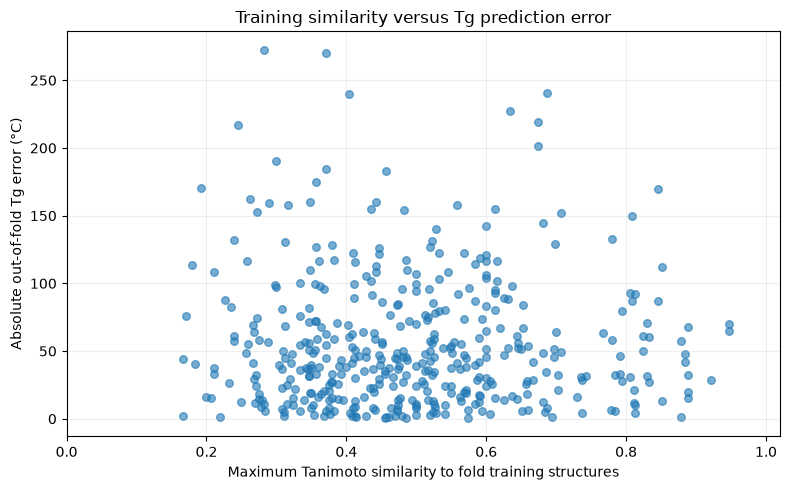

In [16]:
# Create approximately equally sized similarity groups.
similarity_analysis = tg_similarity_errors.copy()

similarity_analysis["similarity_group"] = pd.qcut(
    similarity_analysis["max_training_similarity"],
    q=4,
    duplicates="drop",
)

# Compare prediction errors across all similarity groups.
similarity_summary = (
    similarity_analysis
    .groupby("similarity_group", observed=True)
    .agg(
        count=("absolute_error", "size"),
        similarity_min=("max_training_similarity", "min"),
        similarity_max=("max_training_similarity", "max"),
        mae=("absolute_error", "mean"),
        median_absolute_error=("absolute_error", "median"),
        mean_signed_error=("signed_error", "mean"),
    )
)

display(similarity_summary.round(3))

# Plot every structure, not only the ten largest errors.
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    similarity_analysis["max_training_similarity"],
    similarity_analysis["absolute_error"],
    alpha=0.6,
    s=30,
)

ax.set(
    xlabel="Maximum Tanimoto similarity to fold training structures",
    ylabel="Absolute out-of-fold Tg error (°C)",
    title="Training similarity versus Tg prediction error",
    xlim=(0, 1.02),
)

ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [17]:
# Reuse the observed-Tg groups from the earlier error analysis.
similarity_analysis["tg_range"] = tg_error_groups["tg_range"]

assert similarity_analysis["tg_range"].notna().all()

# Inspect the Tg distribution within each similarity group.
similarity_tg_summary = (
    similarity_analysis
    .groupby("similarity_group", observed=True)
    .agg(
        count=("observed_tg", "size"),
        tg_min=("observed_tg", "min"),
        tg_median=("observed_tg", "median"),
        tg_max=("observed_tg", "max"),
    )
)

display(similarity_tg_summary.round(2))

# Count structures for each combination of Tg and similarity group.
group_counts = pd.crosstab(
    similarity_analysis["tg_range"],
    similarity_analysis["similarity_group"],
)

# Calculate MAE within each combination.
group_mae = similarity_analysis.pivot_table(
    index="tg_range",
    columns="similarity_group",
    values="absolute_error",
    aggfunc="mean",
    observed=True,
)

print("Number of structures:")
display(group_counts)

print("MAE within each Tg and similarity group (°C):")
display(group_mae.round(2))

,count,tg_min,tg_median,tg_max
similarity_group,,,,
"(0.166, 0.368]",106,-121.52,81.17,419.58
"(0.368, 0.478]",106,-148.03,81.31,472.25
"(0.478, 0.6]",115,-90.53,105.22,456.35
"(0.6, 0.947]",97,-104.34,60.42,435.00


Number of structures:


similarity_group,"(0.166, 0.368]","(0.368, 0.478]","(0.478, 0.6]","(0.6, 0.947]"
tg_range,,,,
"(-148.031, 13.881]",30,25,25,26
"(13.881, 74.54]",21,24,29,32
"(74.54, 164.458]",33,30,27,16
"(164.458, 472.25]",22,27,34,23


MAE within each Tg and similarity group (°C):


similarity_group,"(0.166, 0.368]","(0.368, 0.478]","(0.478, 0.6]","(0.6, 0.947]"
tg_range,,,,
"(-148.031, 13.881]",80.70,74.01,54.09,60.59
"(13.881, 74.54]",28.89,19.94,35.55,45.28
"(74.54, 164.458]",40.68,36.80,62.80,53.87
"(164.458, 472.25]",92.57,73.89,62.90,78.66


## 8. Test complementary structure representations

Error does not consistently decrease with nearest-training similarity,
including within the observed Tg groups.

Test whether combining the existing 21 descriptors with Morgan
fingerprints improves Tg predictions.

Compare three representations using the same fixed Random Forest,
labelled rows and five CV folds:
- Morgan fingerprints alone.
- The 21 descriptors alone.
- Morgan fingerprints combined with the 21 descriptors.

This is a development experiment. Keep the outer validation unused
and retain all original target values.

In [18]:
# Load the descriptors already calculated in notebook 06.
descriptor_path = (
    PROJECT_ROOT
    / "results"
    / "06_shared_split"
    / "expanded21_features.csv"
)

assert descriptor_path.is_file(), (
    f"Missing descriptor file: {descriptor_path}"
)

expanded21 = pd.read_csv(
    descriptor_path,
    index_col="row_index",
)

assert expanded21.index.is_unique
assert expanded21.shape[1] == 21
assert set(X_tg.index).issubset(expanded21.index)
assert set(expanded21.columns).isdisjoint(
    {"id", "SMILES", "Tg", "FFV", "Tc", "Density", "Rg"}
)

# Select exactly the same Tg training rows and order.
X_tg_descriptors = expanded21.loc[X_tg.index].copy()

assert np.isfinite(X_tg_descriptors.to_numpy(dtype=float)).all()

# Prefix descriptor names to keep the feature origins clear.
X_tg_combined = pd.concat(
    [
        X_tg,
        X_tg_descriptors.add_prefix("descriptor_"),
    ],
    axis=1,
)

assert X_tg_descriptors.index.equals(y_tg.index)
assert X_tg_combined.index.equals(y_tg.index)
assert X_tg_combined.columns.is_unique
assert X_tg_combined.shape[1] == 1045

print("Morgan only:", X_tg.shape)
print("Descriptors only:", X_tg_descriptors.shape)
print("Combined:", X_tg_combined.shape)

Morgan only: (424, 1024)
Descriptors only: (424, 21)
Combined: (424, 1045)


In [19]:
# Reuse the verified Morgan predictions and fold results.
representation_oof = {
    "morgan1024": tg_errors["predicted_tg"].copy()
}

representation_fold_results = [
    tg_fold_results.assign(representation="morgan1024")
]

# Evaluate the two additional representations.
candidate_features = {
    "descriptors21": X_tg_descriptors,
    "morgan_plus21": X_tg_combined,
}

for representation, features in candidate_features.items():
    assert features.index.equals(y_tg.index)

    predictions_oof = np.full(len(y_tg), np.nan)
    prediction_counts = np.zeros(len(y_tg), dtype=int)
    fold_rows = []

    for fold_number, (train_positions, held_out_positions) in enumerate(
        tg_cv_folds,
        start=1,
    ):
        model = make_model("random_forest", n_jobs=1)

        model.fit(
            features.iloc[train_positions],
            y_tg.iloc[train_positions],
        )

        predictions = model.predict(
            features.iloc[held_out_positions]
        )

        predictions_oof[held_out_positions] = predictions
        prediction_counts[held_out_positions] += 1

        fold_rows.append({
            "representation": representation,
            "fold": fold_number,
            "held_out_rows": len(held_out_positions),
            "mae": mae(
                y_tg.iloc[held_out_positions],
                predictions,
            ),
        })

    assert (prediction_counts == 1).all()
    assert np.isfinite(predictions_oof).all()

    representation_oof[representation] = pd.Series(
        predictions_oof,
        index=y_tg.index,
        name=representation,
    )

    representation_fold_results.append(pd.DataFrame(fold_rows))

    print(f"Completed: {representation}")

# Combine fold-level results.
tg_representation_folds = pd.concat(
    representation_fold_results,
    ignore_index=True,
)

# Summarise the five fold MAEs for each representation.
tg_representation_summary = (
    tg_representation_folds
    .groupby("representation")
    .agg(
        mean_cv_mae=("mae", "mean"),
        std_cv_mae=("mae", "std"),
    )
)

reference_mae = tg_representation_summary.loc[
    "morgan1024", "mean_cv_mae"
]

tg_representation_summary["mae_reduction_vs_morgan_pct"] = (
    100
    * (
        reference_mae
        - tg_representation_summary["mean_cv_mae"]
    )
    / reference_mae
)

display(
    tg_representation_summary
    .sort_values("mean_cv_mae")
    .round(6)
)

display(
    tg_representation_folds.pivot(
        index="fold",
        columns="representation",
        values="mae",
    ).round(6)
)

Completed: descriptors21
Completed: morgan_plus21


,mean_cv_mae,std_cv_mae,mae_reduction_vs_morgan_pct
representation,,,
morgan_plus21,53.880564,5.105404,3.848550
morgan1024,56.037183,7.890153,0.000000
descriptors21,56.986610,4.449933,-1.694279


representation,descriptors21,morgan1024,morgan_plus21
fold,,,
1,54.213529,50.228072,50.863987
2,57.516791,54.707263,54.046718
3,51.057608,48.715243,47.299001
4,62.233055,58.007778,56.681470
5,59.912065,68.527561,60.511644


### Findings from combining representations

Combining Morgan fingerprints with 21 descriptors reduced mean
five-fold CV MAE from 56.037183 °C to 53.880564 °C,
a relative reduction of 3.85%.

- Four of five folds improved compared with Morgan alone.
- Fold 5 improved from 68.527561 °C to 60.511644 °C.
- Fold 1 became slightly worse.
- The standard deviation of fold MAEs decreased from 7.890153 °C
  to 5.105404 °C.

The combined representation performed best among these three
representations with the fixed Random Forest configuration.

These are development CV results. The outer validation remains unused.

In [20]:
# Compare row-level errors using the existing observed-Tg groups.
representation_range_rows = []

for representation, predictions in representation_oof.items():
    assert predictions.index.equals(y_tg.index)

    comparison = pd.DataFrame({
        "observed_tg": y_tg,
        "predicted_tg": predictions,
    })

    comparison["signed_error"] = (
        comparison["predicted_tg"] - comparison["observed_tg"]
    )
    comparison["absolute_error"] = comparison["signed_error"].abs()

    # Reuse the same Tg groups for every representation.
    comparison["tg_range"] = tg_error_groups["tg_range"]

    assert comparison["tg_range"].notna().all()

    range_results = (
        comparison
        .groupby("tg_range", observed=True)
        .agg(
            count=("absolute_error", "size"),
            mae=("absolute_error", "mean"),
            mean_signed_error=("signed_error", "mean"),
        )
        .reset_index()
    )

    range_results["representation"] = representation
    representation_range_rows.append(range_results)

tg_representation_ranges = pd.concat(
    representation_range_rows,
    ignore_index=True,
)

print("MAE by observed Tg range (°C):")
display(
    tg_representation_ranges.pivot(
        index="tg_range",
        columns="representation",
        values="mae",
    ).round(2)
)

print("Mean signed error by observed Tg range (°C):")
display(
    tg_representation_ranges.pivot(
        index="tg_range",
        columns="representation",
        values="mean_signed_error",
    ).round(2)
)

MAE by observed Tg range (°C):


representation,descriptors21,morgan1024,morgan_plus21
tg_range,,,
"(-148.031, 13.881]",61.53,67.91,63.47
"(13.881, 74.54]",35.62,33.63,32.07
"(74.54, 164.458]",52.19,47.21,48.32
"(164.458, 472.25]",78.59,75.28,71.60


Mean signed error by observed Tg range (°C):


representation,descriptors21,morgan1024,morgan_plus21
tg_range,,,
"(-148.031, 13.881]",59.24,66.01,61.78
"(13.881, 74.54]",18.52,11.72,14.30
"(74.54, 164.458]",-20.07,-16.43,-16.16
"(164.458, 472.25]",-67.05,-68.84,-62.95


### Performance across observed Tg ranges

Compared with Morgan alone, the combined representation reduced MAE
in three of four observed Tg groups. MAE increased slightly in the
third group, from 47.21 °C to 48.32 °C.

The 21 descriptors alone performed best in the lowest Tg group
(MAE: 61.53 °C).

For the combined representation, mean signed error changed:
- Lowest Tg group: +66.01 °C to +61.78 °C.
- Highest Tg group: -68.84 °C to -62.95 °C.

The combined representation partly reduced the extreme-range bias,
but substantial overprediction and underprediction remain.
A lower MAE does not necessarily imply a smaller mean signed error.

In [21]:
# Store notebook 07 results separately from notebook 06.
TG_EXPERIMENT_DIR = (
    PROJECT_ROOT / "results" / "07_tg_error_analysis"
)
TG_EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

# Preserve row identifiers, reference errors and training similarity.
oof_export = tg_similarity_errors.copy()

# Add predictions and errors for every tested representation.
for representation, predictions in representation_oof.items():
    assert predictions.index.equals(oof_export.index)

    oof_export[f"{representation}_prediction"] = predictions

    signed_error = predictions - oof_export["observed_tg"]
    oof_export[f"{representation}_signed_error"] = signed_error
    oof_export[f"{representation}_absolute_error"] = signed_error.abs()

oof_export.to_csv(
    TG_EXPERIMENT_DIR / "tg_oof_predictions_and_errors.csv",
    index_label="row_index",
)

# Save numerical results without rounding.
result_tables = {
    "representation_summary.csv": tg_representation_summary,
    "representation_fold_results.csv": tg_representation_folds,
    "representation_tg_ranges.csv": tg_representation_ranges,
    "similarity_summary.csv": similarity_summary,
    "reference_fold_comparison.csv": tg_fold_comparison,
}

for filename, result_table in result_tables.items():
    result_table.to_csv(TG_EXPERIMENT_DIR / filename, index=True)

# Record the settings needed to reproduce this experiment.
experiment_settings = {
    "target": "Tg",
    "training_labels": len(y_tg),
    "outer_validation_used": False,
    "split_random_state": 42,
    "validation_fraction": 0.20,
    "cv_n_splits": 5,
    "cv_shuffle": True,
    "cv_random_state": 42,
    "morgan_settings": morgan_settings,
    "random_forest_parameters": make_model(
        "random_forest", n_jobs=1
    ).get_params(),
}

with (
    TG_EXPERIMENT_DIR / "experiment_settings.json"
).open("w", encoding="utf-8") as file:
    json.dump(experiment_settings, file, indent=2)

print("Results saved to:", TG_EXPERIMENT_DIR)

Results saved to: C:\Users\EMS-User\capstone_virtual_lab_mohamed_suhmi\results\07_tg_error_analysis


## 9. Exploratory structural clustering

Cluster the 424 labelled Tg training structures using Morgan
fingerprints and Tanimoto distance.

Use Butina clustering with an initial distance threshold of 0.60,
equivalent to a similarity threshold of 0.40 for neighbourhoods.

Create clusters using structural information only.
Do not use Tg values or prediction errors to select the threshold.

This clustering describes the development data. It is not a new
cross-validation evaluation or evidence of improved prediction quality.
The outer validation remains unused.

In [22]:
from rdkit.ML.Cluster import Butina

# Define an initial exploratory threshold.
CLUSTER_DISTANCE_THRESHOLD = 0.60

assert len(tg_bit_fingerprints) == len(X_tg)

# Calculate each pairwise distance once.
# Tanimoto distance = 1 - Tanimoto similarity.
pairwise_distances = []

for position in range(1, len(tg_bit_fingerprints)):
    similarities = DataStructs.BulkTanimotoSimilarity(
        tg_bit_fingerprints[position],
        tg_bit_fingerprints[:position],
    )

    pairwise_distances.extend(
        1.0 - similarity
        for similarity in similarities
    )

assert len(pairwise_distances) == len(X_tg) * (len(X_tg) - 1) // 2

# Form clusters without using target values or errors.
tg_clusters = Butina.ClusterData(
    pairwise_distances,
    nPts=len(tg_bit_fingerprints),
    distThresh=CLUSTER_DISTANCE_THRESHOLD,
    isDistData=True,
    reordering=True,
)

# Map cluster membership back to the original row indices.
cluster_ids = np.full(len(X_tg), -1, dtype=int)

for cluster_number, member_positions in enumerate(
    tg_clusters,
    start=1,
):
    cluster_ids[list(member_positions)] = cluster_number

assert (cluster_ids > 0).all()
assert sum(len(cluster) for cluster in tg_clusters) == len(X_tg)

tg_cluster_assignments = pd.Series(
    cluster_ids,
    index=X_tg.index,
    name="cluster",
)

cluster_sizes = (
    tg_cluster_assignments
    .value_counts()
    .rename_axis("cluster")
    .to_frame("structures")
    .sort_values("structures", ascending=False)
)

print("Structures:", len(X_tg))
print("Clusters:", len(cluster_sizes))
print("Singleton clusters:", cluster_sizes["structures"].eq(1).sum())
print("Largest cluster:", cluster_sizes["structures"].max())

display(cluster_sizes.head(15))

Structures: 424
Clusters: 215
Singleton clusters: 148
Largest cluster: 37


,structures
cluster,
1,37
2,27
3,18
4,9
7,7
6,7
5,7
8,6
9,5


### Initial cluster structure

Butina clustering at Tanimoto distance threshold 0.60 produced:
- 215 clusters from 424 structures.
- 148 singleton clusters, containing 34.9% of the structures.
- 67 clusters with at least two members.
- A largest cluster containing 37 structures.

The grouping depends on the fingerprint representation and threshold.
Singleton membership does not establish chemical uniqueness.

Inspect errors in the larger clusters descriptively.
These results do not justify training a separate model per cluster.

In [23]:
# Attach structural groups to the existing out-of-fold errors.
cluster_analysis = tg_errors.join(
    tg_cluster_assignments,
    validate="one_to_one",
)

assert cluster_analysis["cluster"].notna().all()

# Add errors from the combined representation.
combined_predictions = representation_oof["morgan_plus21"]
assert combined_predictions.index.equals(cluster_analysis.index)

cluster_analysis["combined_signed_error"] = (
    combined_predictions - cluster_analysis["observed_tg"]
)
cluster_analysis["combined_absolute_error"] = (
    cluster_analysis["combined_signed_error"].abs()
)

# Summarise all clusters, retaining their sample sizes.
tg_cluster_summary = (
    cluster_analysis
    .groupby("cluster")
    .agg(
        count=("observed_tg", "size"),
        tg_min=("observed_tg", "min"),
        tg_max=("observed_tg", "max"),
        morgan_mae=("absolute_error", "mean"),
        combined_mae=("combined_absolute_error", "mean"),
        combined_mean_signed_error=("combined_signed_error", "mean"),
    )
)

tg_cluster_summary["mae_change"] = (
    tg_cluster_summary["combined_mae"]
    - tg_cluster_summary["morgan_mae"]
)

# Display the largest groups first.
display(
    tg_cluster_summary
    .sort_values("count", ascending=False)
    .head(10)
    .round(2)
)

,count,tg_min,tg_max,morgan_mae,combined_mae,combined_mean_signed_error,mae_change
cluster,,,,,,,
1,37,-71.28,112.53,35.84,33.25,2.80,-2.59
2,27,6.57,245.24,51.84,46.08,-1.62,-5.76
3,18,-71.68,357.30,70.45,64.80,18.75,-5.66
4,9,-64.13,135.05,43.97,48.49,14.71,4.51
5,7,-90.53,148.85,67.36,60.58,25.18,-6.78
6,7,-84.72,149.16,70.90,62.42,14.69,-8.48
7,7,271.26,456.35,66.66,109.61,-70.58,42.95
8,6,36.87,235.69,83.65,95.58,11.79,11.94
9,5,149.91,268.46,33.38,41.79,-21.62,8.41


Cluster 7: 7 structures. Showing 6 examples.


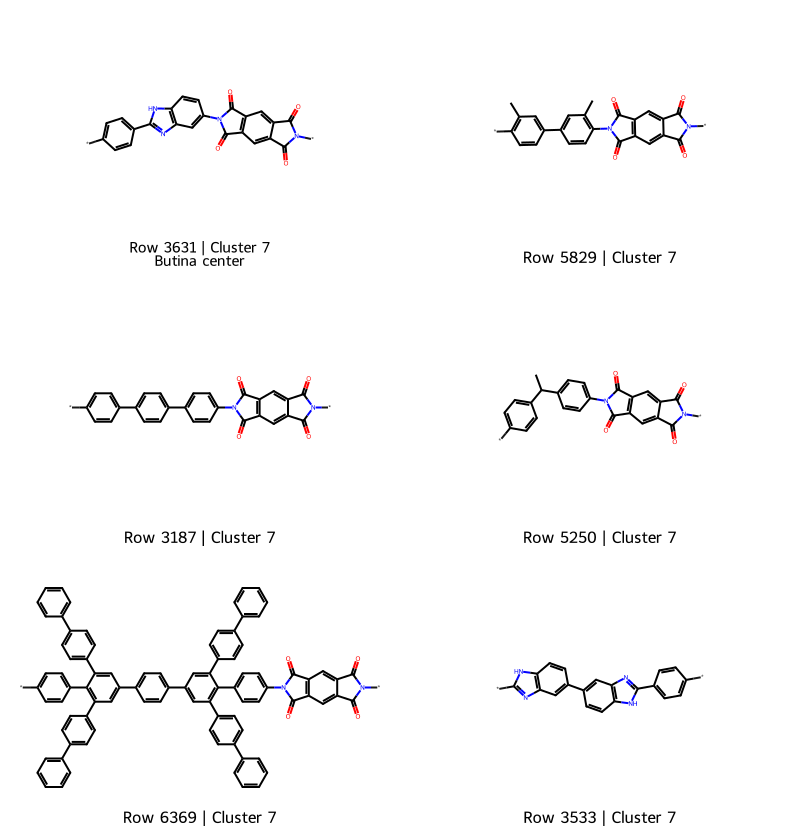

In [26]:
from rdkit.Chem import Draw

SELECTED_CLUSTER = 7

# The first member is the center selected by the Butina algorithm.
member_positions = list(tg_clusters[SELECTED_CLUSTER - 1])
example_positions = member_positions[:6]
example_rows = X_tg.index[example_positions]

example_molecules = tg_molecules.loc[example_rows].tolist()

example_legends = [
    f"Row {row_index} | Cluster {SELECTED_CLUSTER}"
    + ("\nButina center" if position == 0 else "")
    for position, row_index in enumerate(example_rows)
]

print(
    f"Cluster {SELECTED_CLUSTER}: {len(member_positions)} structures. "
    f"Showing {len(example_rows)} examples."
)

display(
    Draw.MolsToGridImage(
        example_molecules,
        legends=example_legends,
        molsPerRow=2,
        subImgSize=(400, 280),
        useSVG=True,
    )
)


In [27]:
# Inspect all seven structures using their existing OOF predictions.
cluster7_details = cluster_analysis.loc[
    cluster_analysis["cluster"].eq(7),
    ["observed_tg", "predicted_tg", "fold", "absolute_error"],
].copy()

cluster7_details = cluster7_details.rename(
    columns={
        "predicted_tg": "morgan_prediction",
        "absolute_error": "morgan_absolute_error",
    }
)

cluster7_details["combined_prediction"] = (
    representation_oof["morgan_plus21"].loc[cluster7_details.index]
)
cluster7_details["combined_absolute_error"] = (
    cluster7_details["combined_prediction"]
    - cluster7_details["observed_tg"]
).abs()

display(
    cluster7_details.sort_values(
        "combined_absolute_error", ascending=False
    ).round(2)
)

,observed_tg,morgan_prediction,fold,morgan_absolute_error,combined_prediction,combined_absolute_error
6369,435.00,282.77,2,152.23,221.92,213.08
3631,456.35,335.57,4,120.78,307.60,148.75
3533,423.63,344.00,1,79.63,292.88,130.75
2551,340.59,368.11,2,27.53,244.46,96.12
3187,278.52,327.59,1,49.07,357.66,79.14
5829,271.26,276.02,2,4.76,328.74,57.48
5250,307.26,274.62,5,32.65,265.30,41.96


### Cluster-specific findings

The combined representation reduced the overall mean fold MAE
from 56.04 to 53.88 °C. However, performance varied across
structural clusters.

In cluster 7 (seven structures), the MAE increased from 66.66
to 109.61 °C. All seven structures had larger absolute OOF
errors with the combined representation. These cases occurred
across four different folds.

This exploratory finding shows that an overall improvement
can coexist with worse predictions for a particular subgroup.
The cause remains unresolved, and the small subgroup does
not justify a cluster-specific modeling rule.

In [28]:
# Save the exploratory clustering results.
tg_cluster_assignments.to_csv(
    TG_EXPERIMENT_DIR / "cluster_assignments.csv",
    index_label="row_index",
)

tg_cluster_summary.to_csv(
    TG_EXPERIMENT_DIR / "cluster_error_summary.csv",
    index_label="cluster",
)

cluster7_details.to_csv(
    TG_EXPERIMENT_DIR / "cluster7_prediction_details.csv",
    index_label="row_index",
)

clustering_settings = {
    "method": "Butina",
    "distance": "1 - Morgan fingerprint Tanimoto similarity",
    "distance_threshold": float(CLUSTER_DISTANCE_THRESHOLD),
    "reordering": True,
    "n_structures": int(len(tg_cluster_assignments)),
    "n_clusters": int(len(tg_clusters)),
    "purpose": "Exploratory analysis of existing OOF errors",
}

with (
    TG_EXPERIMENT_DIR / "clustering_settings.json"
).open("w", encoding="utf-8") as file:
    json.dump(clustering_settings, file, indent=2)

print("Clustering results saved to:", TG_EXPERIMENT_DIR)

Clustering results saved to: C:\Users\EMS-User\capstone_virtual_lab_mohamed_suhmi\results\07_tg_error_analysis


morgan1024 | Fold 1/5 | MAE: 55.17 °C
morgan1024 | Fold 2/5 | MAE: 55.61 °C
morgan1024 | Fold 3/5 | MAE: 53.65 °C
morgan1024 | Fold 4/5 | MAE: 53.50 °C
morgan1024 | Fold 5/5 | MAE: 63.86 °C
morgan_plus21 | Fold 1/5 | MAE: 50.86 °C
morgan_plus21 | Fold 2/5 | MAE: 49.37 °C
morgan_plus21 | Fold 3/5 | MAE: 47.25 °C
morgan_plus21 | Fold 4/5 | MAE: 57.05 °C
morgan_plus21 | Fold 5/5 | MAE: 67.31 °C

CV comparison — MAE in °C:


,random_cv_mae,random_cv_std,grouped_cv_mae,grouped_cv_std,overall_oof_mae,grouped_minus_random_mae
representation,,,,,,
morgan1024,56.037,7.890,56.360,4.294,56.342,0.322
morgan_plus21,53.881,5.105,54.367,8.100,54.337,0.487



Grouped fold results — MAE in °C:


representation,morgan1024,morgan_plus21
fold,,
1,55.165,50.865
2,55.613,49.368
3,53.652,47.253
4,53.504,57.046
5,63.863,67.306



Fold composition — no cluster overlap:


,fold,training_rows,held_out_rows,training_clusters,held_out_clusters,held_out_tg_min,held_out_tg_max
0,1,339,85,176,39,-71.28,437.49
1,2,339,85,173,42,-104.34,325.29
2,3,339,85,171,44,-71.68,472.25
3,4,339,85,170,45,-148.03,411.97
4,5,340,84,170,45,-128.63,456.35


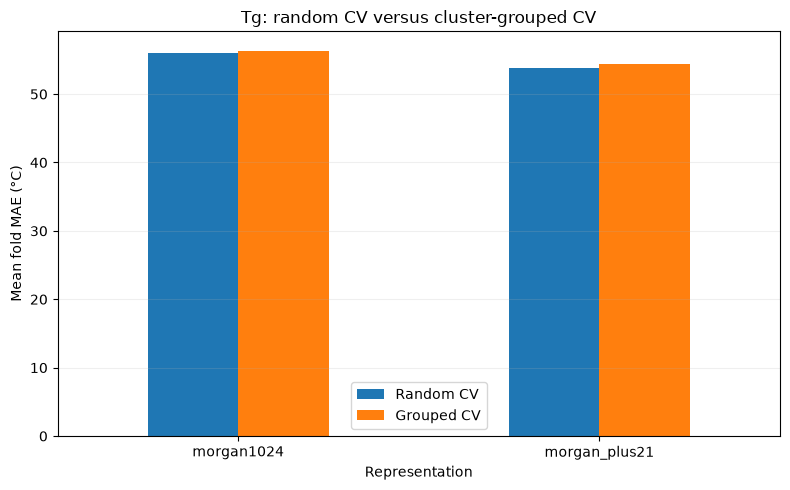


Combined representation: grouped-CV MAE reduction versus Morgan = 3.53% (positive = improvement).
No cluster overlaps between training and held-out rows.
The outer validation set was not used.
Different clusters can still contain similar structures.
This is an exploratory comparison, not an independent final test.
Results saved to: C:\Users\EMS-User\capstone_virtual_lab_mohamed_suhmi\results\07_tg_error_analysis
Elapsed time: 37.7 seconds


In [29]:
# Final clustering experiment: grouped CV versus existing random CV.
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from src.polymer_modeling import make_model, mae

started = time.perf_counter()

# 1. Check alignment and prepare identical grouped folds.
groups = tg_cluster_assignments.loc[X_tg.index]
assert X_tg.index.equals(y_tg.index)
assert X_tg_combined.index.equals(y_tg.index)
assert groups.notna().all()
assert groups.nunique() >= 5

grouped_folds = list(
    GroupKFold(n_splits=5).split(X_tg, y_tg, groups=groups)
)

grouped_oof = pd.DataFrame(index=y_tg.index)
grouped_oof.index.name = "row_index"
grouped_oof["observed_tg"] = y_tg
grouped_oof["cluster"] = groups
grouped_oof["fold"] = 0

fold_checks = []
for fold, (train_pos, test_pos) in enumerate(grouped_folds, start=1):
    train_clusters = set(groups.iloc[train_pos])
    test_clusters = set(groups.iloc[test_pos])
    assert train_clusters.isdisjoint(test_clusters)

    grouped_oof.iloc[
        test_pos, grouped_oof.columns.get_loc("fold")
    ] = fold

    fold_checks.append({
        "fold": fold,
        "training_rows": len(train_pos),
        "held_out_rows": len(test_pos),
        "training_clusters": len(train_clusters),
        "held_out_clusters": len(test_clusters),
        "held_out_tg_min": float(y_tg.iloc[test_pos].min()),
        "held_out_tg_max": float(y_tg.iloc[test_pos].max()),
    })

# 2. Compare both representations using the same fixed RF settings.
representations = {
    "morgan1024": X_tg,
    "morgan_plus21": X_tg_combined,
}
fold_records = []

for representation, features in representations.items():
    predictions = np.full(len(y_tg), np.nan)
    prediction_counts = np.zeros(len(y_tg), dtype=int)

    for fold, (train_pos, test_pos) in enumerate(grouped_folds, start=1):
        model = make_model("random_forest", n_jobs=1)
        model.fit(features.iloc[train_pos], y_tg.iloc[train_pos])

        fold_predictions = model.predict(features.iloc[test_pos])
        predictions[test_pos] = fold_predictions
        prediction_counts[test_pos] += 1

        fold_mae = mae(y_tg.iloc[test_pos], fold_predictions)
        fold_records.append({
            "representation": representation,
            "fold": fold,
            "held_out_rows": len(test_pos),
            "mae": fold_mae,
        })
        print(f"{representation} | Fold {fold}/5 | MAE: {fold_mae:.2f} °C")

    assert np.all(prediction_counts == 1)
    assert np.isfinite(predictions).all()

    grouped_oof[f"{representation}_prediction"] = predictions
    grouped_oof[f"{representation}_signed_error"] = predictions - y_tg.to_numpy()
    grouped_oof[f"{representation}_absolute_error"] = np.abs(
        predictions - y_tg.to_numpy()
    )

# 3. Summarize grouped CV and compare with the existing random CV.
grouped_fold_results = pd.DataFrame(fold_records)
grouped_summary = grouped_fold_results.groupby("representation").agg(
    mean_cv_mae=("mae", "mean"),
    std_cv_mae=("mae", "std"),
)

for representation in representations:
    grouped_summary.loc[representation, "overall_oof_mae"] = (
        grouped_oof[f"{representation}_absolute_error"].mean()
    )

random_summary = tg_representation_summary.loc[
    list(representations), ["mean_cv_mae", "std_cv_mae"]
].copy()

cv_comparison = random_summary.rename(columns={
    "mean_cv_mae": "random_cv_mae",
    "std_cv_mae": "random_cv_std",
}).join(
    grouped_summary.rename(columns={
        "mean_cv_mae": "grouped_cv_mae",
        "std_cv_mae": "grouped_cv_std",
    })
)
cv_comparison["grouped_minus_random_mae"] = (
    cv_comparison["grouped_cv_mae"] - cv_comparison["random_cv_mae"]
)

print("\nCV comparison — MAE in °C:")
display(cv_comparison.round(3))

print("\nGrouped fold results — MAE in °C:")
display(grouped_fold_results.pivot(
    index="fold", columns="representation", values="mae"
).round(3))

print("\nFold composition — no cluster overlap:")
display(pd.DataFrame(fold_checks).round(2))

# 4. Plot the two evaluation protocols.
ax = cv_comparison[["random_cv_mae", "grouped_cv_mae"]].rename(
    columns={"random_cv_mae": "Random CV", "grouped_cv_mae": "Grouped CV"}
).plot.bar(figsize=(8, 5), rot=0)

ax.set(
    title="Tg: random CV versus cluster-grouped CV",
    xlabel="Representation",
    ylabel="Mean fold MAE (°C)",
)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
ax.figure.savefig(
    TG_EXPERIMENT_DIR / "random_vs_grouped_cv.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

# 5. Save results and the exact group/fold assignments.
grouped_fold_results.to_csv(
    TG_EXPERIMENT_DIR / "grouped_cv_fold_results.csv", index=False
)
grouped_summary.to_csv(TG_EXPERIMENT_DIR / "grouped_cv_summary.csv")
cv_comparison.to_csv(TG_EXPERIMENT_DIR / "random_vs_grouped_cv.csv")
grouped_oof.to_csv(TG_EXPERIMENT_DIR / "grouped_cv_oof_predictions.csv")
pd.DataFrame(fold_checks).to_csv(
    TG_EXPERIMENT_DIR / "grouped_cv_fold_composition.csv", index=False
)
tg_cluster_summary.to_csv(
    TG_EXPERIMENT_DIR / "cluster_error_summary.csv"
)
cluster7_details.to_csv(
    TG_EXPERIMENT_DIR / "cluster7_prediction_details.csv",
    index_label="row_index",
)

settings = {
    "purpose": "Exploratory cluster-grouped robustness check",
    "target": "Tg",
    "n_structures": int(len(y_tg)),
    "n_clusters": int(groups.nunique()),
    "clustering_method": "Butina",
    "cluster_distance_threshold": float(CLUSTER_DISTANCE_THRESHOLD),
    "clustering_reordering": True,
    "morgan_settings": morgan_settings,
    "cv": "GroupKFold",
    "n_splits": 5,
    "shuffle": False,
    "representations": list(representations),
    "model_parameters": make_model("random_forest", n_jobs=1).get_params(),
    "outer_validation_used": False,
}

with (TG_EXPERIMENT_DIR / "grouped_cv_settings.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(settings, file, indent=2)

grouped_reduction = 100 * (
    grouped_summary.loc["morgan1024", "mean_cv_mae"]
    - grouped_summary.loc["morgan_plus21", "mean_cv_mae"]
) / grouped_summary.loc["morgan1024", "mean_cv_mae"]

print(
    "\nCombined representation: grouped-CV MAE reduction versus Morgan "
    f"= {grouped_reduction:.2f}% (positive = improvement)."
)
print("No cluster overlaps between training and held-out rows.")
print("The outer validation set was not used.")
print("Different clusters can still contain similar structures.")
print("This is an exploratory comparison, not an independent final test.")
print(f"Results saved to: {TG_EXPERIMENT_DIR}")
print(f"Elapsed time: {time.perf_counter() - started:.1f} seconds")

### Conclusion of the exploratory clustering analysis

Holding out complete Butina clusters increased the mean fold MAE
only slightly: from 56.04 to 56.36 °C for Morgan fingerprints,
and from 53.88 to 54.37 °C for Morgan plus 21 descriptors.

The combined representation retained an average advantage of
3.53% under grouped CV, improving three of the five folds.
However, subgroup weaknesses remained, including cluster 7
in the earlier random-CV error analysis.

These results support retaining the combined representation
as a candidate. This single exploratory grouped split does
not establish generalization to new polymer families.
Different clusters can still contain similar structures.

All calculations used the 424 observed Tg labels in the
training partition. The outer validation set remained unused.

### Fazit der explorativen Clusteranalyse

Das Zurückhalten vollständiger Butina-Cluster erhöhte den mittleren
MAE über die Folds nur geringfügig: bei Morgan-Fingerprints von
56,04 auf 56,36 °C und bei Morgan plus 21 Deskriptoren von
53,88 auf 54,37 °C.

Die kombinierte Darstellung behielt bei der gruppierten
Kreuzvalidierung einen durchschnittlichen Vorteil von 3,53 %.
Sie verbesserte die Ergebnisse in drei der fünf Folds.
Schwächen in einzelnen Teilgruppen blieben jedoch bestehen,
darunter Cluster 7 in der vorherigen Fehleranalyse mit
zufälliger Kreuzvalidierung.

Diese Ergebnisse sprechen dafür, die kombinierte Darstellung
als Kandidaten beizubehalten. Diese einzelne explorative
Gruppenaufteilung belegt jedoch noch keine Übertragbarkeit
auf neue Polymerfamilien. Verschiedene Cluster können
weiterhin ähnliche Strukturen enthalten.

Alle Berechnungen verwendeten die 424 vorhandenen Tg-Zielwerte
aus der Trainingspartition. Das äußere Validierungsset
blieb unbenutzt.

extra_trees | Fold 1/5 | MAE: 53.95 °C
extra_trees | Fold 2/5 | MAE: 57.89 °C
extra_trees | Fold 3/5 | MAE: 50.52 °C
extra_trees | Fold 4/5 | MAE: 61.04 °C
extra_trees | Fold 5/5 | MAE: 71.07 °C
Completed in 30.1 seconds.

ridge_alpha100 | Fold 1/5 | MAE: 62.72 °C
ridge_alpha100 | Fold 2/5 | MAE: 64.80 °C
ridge_alpha100 | Fold 3/5 | MAE: 60.46 °C
ridge_alpha100 | Fold 4/5 | MAE: 70.63 °C
ridge_alpha100 | Fold 5/5 | MAE: 68.83 °C
Completed in 0.5 seconds.

Model comparison — lower MAE is better:


,mean_cv_mae,std_cv_mae,overall_oof_mae,mae_reduction_vs_rf_pct
model,,,,
random_forest,53.881,5.105,53.865,0.000
extra_trees,58.893,7.884,58.865,-9.304
ridge_alpha100,65.488,4.215,65.480,-21.542



MAE by fold:


model,extra_trees,random_forest,ridge_alpha100
fold,,,
1,53.945,50.864,62.723
2,57.892,54.047,64.798
3,50.515,47.299,60.456
4,61.044,56.681,70.628
5,71.071,60.512,68.834


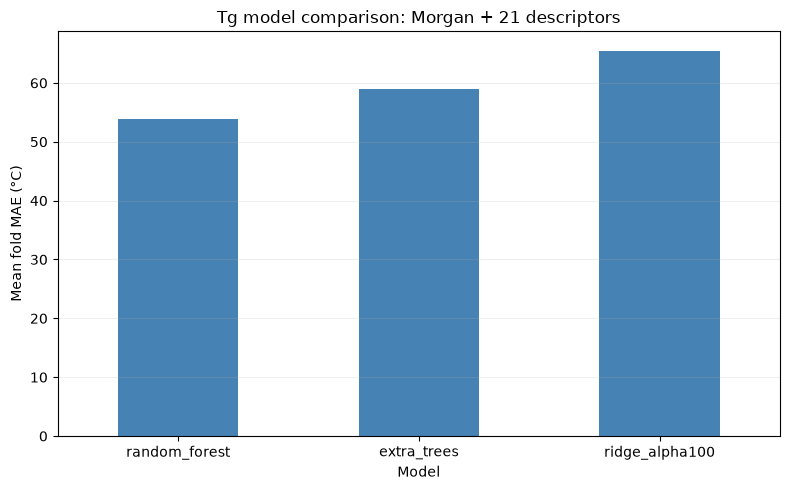

Saved to: C:\Users\EMS-User\capstone_virtual_lab_mohamed_suhmi\results\07_tg_model_comparison
The outer validation set remained unused.


In [30]:
# Compact Tg model comparison on Morgan fingerprints + 21 descriptors.
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

MODEL_COMPARISON_DIR = PROJECT_ROOT / "results" / "07_tg_model_comparison"
MODEL_COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

assert X_tg_combined.index.equals(y_tg.index)
assert np.isfinite(X_tg_combined.to_numpy()).all()
assert np.isfinite(y_tg.to_numpy()).all()

# Fixed configurations for an initial comparison, not a tuning search.
candidate_models = {
    "extra_trees": ExtraTreesRegressor(
        n_estimators=200,
        max_features=1.0,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=1,
    ),
    "ridge_alpha100": make_pipeline(
        StandardScaler(),
        Ridge(alpha=100.0, solver="lsqr"),
    ),
}

model_oof = pd.DataFrame(index=y_tg.index)
model_oof.index.name = "row_index"
model_oof["observed_tg"] = y_tg
model_oof["fold"] = 0

# Reuse the existing RF predictions from exactly the same CV folds.
rf_predictions = representation_oof["morgan_plus21"]
assert rf_predictions.index.equals(y_tg.index)
assert np.isfinite(rf_predictions.to_numpy()).all()
model_oof["random_forest"] = rf_predictions

model_fold_records = []

for fold, (_, test_pos) in enumerate(tg_cv_folds, start=1):
    model_oof.iloc[test_pos, model_oof.columns.get_loc("fold")] = fold
    model_fold_records.append({
        "model": "random_forest",
        "fold": fold,
        "held_out_rows": len(test_pos),
        "mae": mae(
            y_tg.iloc[test_pos],
            rf_predictions.iloc[test_pos],
        ),
    })

# Train only the two new candidates.
for model_name, estimator in candidate_models.items():
    started = time.perf_counter()
    predictions = np.full(len(y_tg), np.nan)
    prediction_counts = np.zeros(len(y_tg), dtype=int)

    for fold, (train_pos, test_pos) in enumerate(tg_cv_folds, start=1):
        model = clone(estimator)

        # The Ridge scaler is fitted only on this fold's training rows.
        model.fit(
            X_tg_combined.iloc[train_pos],
            y_tg.iloc[train_pos],
        )
        predictions[test_pos] = model.predict(
            X_tg_combined.iloc[test_pos]
        )
        prediction_counts[test_pos] += 1

        fold_mae = mae(y_tg.iloc[test_pos], predictions[test_pos])
        model_fold_records.append({
            "model": model_name,
            "fold": fold,
            "held_out_rows": len(test_pos),
            "mae": fold_mae,
        })
        print(f"{model_name} | Fold {fold}/5 | MAE: {fold_mae:.2f} °C")

    assert np.all(prediction_counts == 1)
    assert np.isfinite(predictions).all()
    model_oof[model_name] = predictions

    print(f"Completed in {time.perf_counter() - started:.1f} seconds.\n")

# Summarize the existing RF and the new candidates consistently.
model_fold_results = pd.DataFrame(model_fold_records)
model_comparison_summary = model_fold_results.groupby("model").agg(
    mean_cv_mae=("mae", "mean"),
    std_cv_mae=("mae", "std"),
)

for model_name in ["random_forest", *candidate_models]:
    model_comparison_summary.loc[model_name, "overall_oof_mae"] = mae(
        y_tg, model_oof[model_name]
    )

rf_mae = model_comparison_summary.loc["random_forest", "mean_cv_mae"]
model_comparison_summary["mae_reduction_vs_rf_pct"] = (
    100 * (rf_mae - model_comparison_summary["mean_cv_mae"]) / rf_mae
)
model_comparison_summary = model_comparison_summary.sort_values("mean_cv_mae")

print("Model comparison — lower MAE is better:")
display(model_comparison_summary.round(3))

print("\nMAE by fold:")
display(
    model_fold_results.pivot(
        index="fold", columns="model", values="mae"
    ).round(3)
)

ax = model_comparison_summary["mean_cv_mae"].plot.bar(
    figsize=(8, 5), rot=0, color="steelblue"
)
ax.set(
    title="Tg model comparison: Morgan + 21 descriptors",
    xlabel="Model",
    ylabel="Mean fold MAE (°C)",
)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
ax.figure.savefig(
    MODEL_COMPARISON_DIR / "model_comparison.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

# Save predictions, scores, and settings.
model_oof.to_csv(MODEL_COMPARISON_DIR / "model_oof_predictions.csv")
model_fold_results.to_csv(
    MODEL_COMPARISON_DIR / "model_fold_results.csv", index=False
)
model_comparison_summary.to_csv(
    MODEL_COMPARISON_DIR / "model_comparison_summary.csv"
)

settings = {
    "target": "Tg",
    "representation": "morgan_plus21",
    "feature_columns": X_tg_combined.columns.tolist(),
    "cv": "Existing five random CV folds from notebook 07",
    "outer_validation_used": False,
    "random_forest": make_model("random_forest", n_jobs=1).get_params(),
    "extra_trees": candidate_models["extra_trees"].get_params(),
    "ridge": {
        "alpha": 100.0,
        "solver": "lsqr",
        "scaling": "StandardScaler fitted inside each training fold",
    },
}

with (MODEL_COMPARISON_DIR / "settings.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(settings, file, indent=2)

print("Saved to:", MODEL_COMPARISON_DIR)
print("The outer validation set remained unused.")

### Compact model comparison

Using Morgan fingerprints plus 21 descriptors and identical
five-fold CV splits, Random Forest achieved the lowest mean
MAE at 53.88 °C.

Extra Trees achieved 58.89 °C, and Ridge regression with
alpha = 100 achieved 65.49 °C. Random Forest performed better
than both alternatives in every fold.

This comparison evaluated one fixed configuration per model.
It does not establish that Random Forest outperforms all
possible configurations of these model families.

Random Forest is retained for a small, targeted
hyperparameter search. The outer validation set remains unused.

In [31]:
# Small, targeted RF search on the existing five CV folds.
from sklearn.base import clone

RF_TUNING_DIR = PROJECT_ROOT / "results" / "07_tg_rf_tuning"
RF_TUNING_DIR.mkdir(parents=True, exist_ok=True)

# Keep 200 trees and all other settings unchanged.
rf_configurations = {
    "rf_reference": {"max_features": 1.0, "min_samples_leaf": 1},
    "rf_features060": {"max_features": 0.6, "min_samples_leaf": 1},
    "rf_features030": {"max_features": 0.3, "min_samples_leaf": 1},
    "rf_features060_leaf2": {"max_features": 0.6, "min_samples_leaf": 2},
}

assert X_tg_combined.index.equals(y_tg.index)

rf_tuning_oof = pd.DataFrame(index=y_tg.index)
rf_tuning_oof.index.name = "row_index"
rf_tuning_oof["observed_tg"] = y_tg
rf_tuning_oof["fold"] = 0

rf_tuning_records = []
rf_base_model = make_model("random_forest", n_jobs=1)

for name, parameters in rf_configurations.items():
    started = time.perf_counter()
    predictions = np.full(len(y_tg), np.nan)
    counts = np.zeros(len(y_tg), dtype=int)

    for fold, (train_pos, test_pos) in enumerate(tg_cv_folds, start=1):
        if name == "rf_reference":
            # Reuse the matching reference predictions.
            reference = representation_oof["morgan_plus21"]
            assert reference.index.equals(y_tg.index)
            predictions[test_pos] = reference.iloc[test_pos].to_numpy()
        else:
            model = clone(rf_base_model).set_params(**parameters)
            model.fit(
                X_tg_combined.iloc[train_pos],
                y_tg.iloc[train_pos],
            )
            predictions[test_pos] = model.predict(
                X_tg_combined.iloc[test_pos]
            )

        counts[test_pos] += 1
        rf_tuning_oof.iloc[
            test_pos, rf_tuning_oof.columns.get_loc("fold")
        ] = fold

        rf_tuning_records.append({
            "configuration": name,
            **parameters,
            "fold": fold,
            "held_out_rows": len(test_pos),
            "mae": mae(y_tg.iloc[test_pos], predictions[test_pos]),
        })

    assert np.all(counts == 1)
    assert np.isfinite(predictions).all()
    rf_tuning_oof[name] = predictions
    print(f"Completed: {name} ({time.perf_counter() - started:.1f} s)")

rf_tuning_folds = pd.DataFrame(rf_tuning_records)
rf_tuning_summary = rf_tuning_folds.groupby("configuration").agg(
    mean_cv_mae=("mae", "mean"),
    std_cv_mae=("mae", "std"),
)

reference_mae = rf_tuning_summary.loc["rf_reference", "mean_cv_mae"]

for name in rf_configurations:
    rf_tuning_summary.loc[name, "overall_oof_mae"] = mae(
        y_tg, rf_tuning_oof[name]
    )

rf_tuning_summary["mae_reduction_vs_reference_pct"] = (
    100 * (reference_mae - rf_tuning_summary["mean_cv_mae"])
    / reference_mae
)
rf_tuning_summary = rf_tuning_summary.sort_values("mean_cv_mae")

rf_tuning_fold_table = rf_tuning_folds.pivot(
    index="fold", columns="configuration", values="mae"
)

print("\nRF tuning comparison — lower MAE is better:")
display(rf_tuning_summary.round(3))

print("\nMAE by fold:")
display(rf_tuning_fold_table.round(3))

best_rf_configuration = rf_tuning_summary.index[0]
print("\nLowest mean CV MAE:", best_rf_configuration)
print("Parameters:", rf_configurations[best_rf_configuration])

rf_tuning_summary.to_csv(RF_TUNING_DIR / "rf_tuning_summary.csv")
rf_tuning_folds.to_csv(
    RF_TUNING_DIR / "rf_tuning_folds.csv", index=False
)
rf_tuning_oof.to_csv(RF_TUNING_DIR / "rf_tuning_oof_predictions.csv")

with (RF_TUNING_DIR / "rf_tuning_settings.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump({
        "representation": "morgan_plus21",
        "base_model_parameters": rf_base_model.get_params(),
        "configurations": rf_configurations,
        "cv": "Existing five random CV folds from notebook 07",
        "selected_configuration": best_rf_configuration,
        "outer_validation_used": False,
    }, file, indent=2)

print("\nSaved to:", RF_TUNING_DIR)
print("Selection uses development CV; the outer validation set remains unused.")

Completed: rf_reference (0.0 s)
Completed: rf_features060 (15.8 s)
Completed: rf_features030 (9.1 s)
Completed: rf_features060_leaf2 (10.1 s)

RF tuning comparison — lower MAE is better:


,mean_cv_mae,std_cv_mae,overall_oof_mae,mae_reduction_vs_reference_pct
configuration,,,,
rf_features060_leaf2,53.139,4.958,53.124,1.377
rf_features060,53.262,5.250,53.245,1.148
rf_features030,53.264,5.402,53.247,1.145
rf_reference,53.881,5.105,53.865,0.000



MAE by fold:


configuration,rf_features030,rf_features060,rf_features060_leaf2,rf_reference
fold,,,,
1,49.423,49.761,50.562,50.864
2,53.025,53.193,53.437,54.047
3,46.855,46.931,46.490,47.299
4,56.797,56.103,55.657,56.681
5,60.218,60.322,59.547,60.512



Lowest mean CV MAE: rf_features060_leaf2
Parameters: {'max_features': 0.6, 'min_samples_leaf': 2}

Saved to: C:\Users\EMS-User\capstone_virtual_lab_mohamed_suhmi\results\07_tg_rf_tuning
Selection uses development CV; the outer validation set remains unused.


In [32]:
# Freeze the selected Tg candidate before outer validation.
selected_tg_parameters = {
    "max_features": 0.6,
    "min_samples_leaf": 2,
}

selected_tg_model = make_model(
    "random_forest", n_jobs=1
).set_params(**selected_tg_parameters)

print(selected_tg_model)

RandomForestRegressor(max_features=0.6, min_samples_leaf=2, n_estimators=200,
                      n_jobs=1, random_state=42)


### Targeted Random Forest tuning

The best tested configuration used max_features = 0.6
and min_samples_leaf = 2, with 200 trees.

The mean five-fold CV MAE decreased from 53.88 to 53.14 °C,
a reduction of 1.38%. This configuration improved the
reference result in all five folds.

The improvement is small and was measured on the same
development folds used for selection. The configuration
is now fixed before evaluation on the outer validation set.

Training rows with observed Tg: 424
Validation rows with observed Tg: 87

Outer validation results — errors in °C:


,validation_rows,mae,rmse,r2,mean_signed_error
model,,,,,
training_median_baseline,87,79.579,102.909,-0.018,-13.817
selected_random_forest,87,45.918,58.828,0.667,1.976


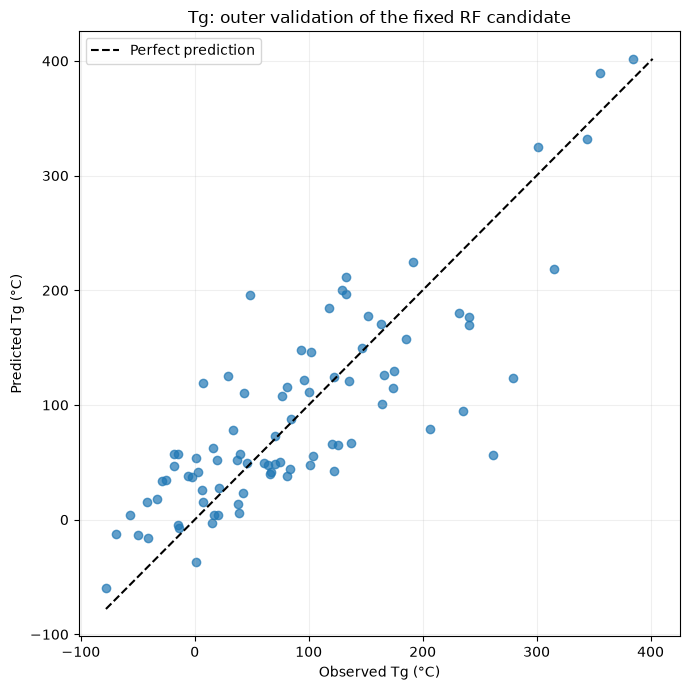

Evaluation saved to: C:\Users\EMS-User\capstone_virtual_lab_mohamed_suhmi\results\07_tg_validation


In [33]:
# Evaluate the fixed Tg candidate on the outer validation partition.
from sklearn.base import clone
from sklearn.metrics import r2_score

TG_VALIDATION_DIR = PROJECT_ROOT / "results" / "07_tg_validation"
TG_VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

# 1. Select validation rows with an observed Tg.
validation_mask = (
    split_by_row["partition"].eq("validation")
    & raw_train["Tg"].notna()
)
tg_validation = raw_train.loc[
    validation_mask, ["id", "SMILES", "Tg"]
].copy()

assert len(tg_validation) > 0
assert X_tg_combined.index.intersection(tg_validation.index).empty
assert set(X_tg_combined.index) == set(
    raw_train.index[training_mask & raw_train["Tg"].notna()]
)

# 2. Build the same features in exactly the same column order.
validation_molecules = tg_validation["SMILES"].map(Chem.MolFromSmiles)
assert validation_molecules.notna().all(), "Invalid validation SMILES."

X_validation_morgan = pd.DataFrame(
    np.stack([
        morgan_generator.GetFingerprintAsNumPy(molecule)
        for molecule in validation_molecules
    ]),
    index=tg_validation.index,
    columns=X_tg.columns,
    dtype=np.uint8,
)

X_validation_descriptors = expanded21.loc[
    tg_validation.index, X_tg_descriptors.columns
].add_prefix("descriptor_")

X_tg_validation = pd.concat(
    [X_validation_morgan, X_validation_descriptors], axis=1
).loc[:, X_tg_combined.columns]

y_tg_validation = tg_validation["Tg"]

assert X_tg_validation.index.equals(y_tg_validation.index)
assert X_tg_validation.columns.equals(X_tg_combined.columns)
assert np.isfinite(X_tg_validation.to_numpy()).all()

# 3. Fit the previously selected configuration on training rows only.
tg_evaluation_model = clone(selected_tg_model)

assert tg_evaluation_model.get_params()["max_features"] == 0.6
assert tg_evaluation_model.get_params()["min_samples_leaf"] == 2
assert tg_evaluation_model.get_params()["n_estimators"] == 200

tg_evaluation_model.fit(X_tg_combined, y_tg)
validation_predictions = tg_evaluation_model.predict(X_tg_validation)

# The baseline uses the training median, never the validation median.
median_predictions = np.full(len(y_tg_validation), y_tg.median())

validation_metrics = []
for name, predictions in {
    "training_median_baseline": median_predictions,
    "selected_random_forest": validation_predictions,
}.items():
    errors = predictions - y_tg_validation.to_numpy()
    validation_metrics.append({
        "model": name,
        "validation_rows": len(y_tg_validation),
        "mae": float(np.abs(errors).mean()),
        "rmse": float(np.sqrt(np.mean(errors ** 2))),
        "r2": float(r2_score(y_tg_validation, predictions)),
        "mean_signed_error": float(errors.mean()),
    })

tg_validation_summary = pd.DataFrame(validation_metrics).set_index("model")

tg_validation_errors = tg_validation.rename(
    columns={"Tg": "observed_tg"}
).copy()
tg_validation_errors["predicted_tg"] = validation_predictions
tg_validation_errors["median_baseline_prediction"] = median_predictions
tg_validation_errors["signed_error"] = (
    tg_validation_errors["predicted_tg"]
    - tg_validation_errors["observed_tg"]
)
tg_validation_errors["absolute_error"] = (
    tg_validation_errors["signed_error"].abs()
)

print("Training rows with observed Tg:", len(y_tg))
print("Validation rows with observed Tg:", len(y_tg_validation))
print("\nOuter validation results — errors in °C:")
display(tg_validation_summary.round(3))

# 4. Visualize and save the evaluation.
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(y_tg_validation, validation_predictions, alpha=0.7)

limits = [
    min(y_tg_validation.min(), validation_predictions.min()),
    max(y_tg_validation.max(), validation_predictions.max()),
]
ax.plot(limits, limits, "k--", label="Perfect prediction")
ax.set(
    title="Tg: outer validation of the fixed RF candidate",
    xlabel="Observed Tg (°C)",
    ylabel="Predicted Tg (°C)",
)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
fig.savefig(
    TG_VALIDATION_DIR / "validation_observed_vs_predicted.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

tg_validation_summary.to_csv(
    TG_VALIDATION_DIR / "validation_summary.csv"
)
tg_validation_errors.to_csv(
    TG_VALIDATION_DIR / "validation_predictions_and_errors.csv",
    index_label="row_index",
)

with (TG_VALIDATION_DIR / "evaluation_settings.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump({
        "target": "Tg",
        "representation": "morgan_plus21",
        "training_rows": len(y_tg),
        "validation_rows": len(y_tg_validation),
        "model_parameters": tg_evaluation_model.get_params(),
        "feature_columns": X_tg_combined.columns.tolist(),
        "morgan_settings": morgan_settings,
        "training_row_indices": [int(i) for i in y_tg.index],
        "validation_row_indices": [int(i) for i in y_tg_validation.index],
        "selection": "Fixed using training CV before this evaluation",
    }, file, indent=2)

print("Evaluation saved to:", TG_VALIDATION_DIR)

### Outer validation of the fixed Tg candidate

The selected Random Forest was trained on 424 structures
with observed Tg and evaluated on 87 held-out validation
structures.

Using Morgan fingerprints plus 21 descriptors, it achieved:
- MAE: 45.92 °C
- RMSE: 58.83 °C
- R²: 0.667
- Mean signed error: +1.98 °C

The training-median baseline achieved an MAE of 79.58 °C.
The selected model reduced MAE by approximately 42.3%
relative to this baseline.

The validation MAE was lower than the development CV MAE
of 53.14 °C. This difference may reflect the composition
of the data split and does not establish further improvement.

Individual large errors remain. This evaluation concerns
one shared random holdout, not an external dataset or
a dedicated test of unseen polymer families.
No further tuning will use these validation results.